# Time Series I: Stationarity, Random Walks & Unit Roots. Solutions
### Applied Statistical Data Analysis. Prof. Dr. Kristyna Ters | MSc Finance | FHNW
**Based on:** Brooks, C., *Introductory Econometrics for Finance*, Cambridge University Press, Ch. 6 and 8

Complete worked solutions for the ten exercises. Each solution shows the code, the numbers, and the interpretation you were expected to give. The quoted numbers refer to the seeded fallback data; with a live download they will differ slightly, the conclusions will not.

---

## Step 0: Data Setup (run this first)

In [1]:
!pip install "statsmodels>=0.15" yfinance --quiet

import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.stattools import durbin_watson
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
import logging
# a download that cannot reach the internet must not leave its own error text
# in the saved output; the notebook falls back to the seeded series instead.
logging.getLogger('yfinance').setLevel(logging.CRITICAL)

# ---- Dataset 1: US 10-year Treasury yield, monthly since 2000, as in the lecture notebook ----
def load_yield():
    try:
        import yfinance as yf
        raw = yf.download('^TNX', start='2000-01-01', progress=False)
        close = raw['Close']
        if isinstance(close, pd.DataFrame):
            close = close.iloc[:, 0]
        close = close.dropna()
        if len(close) < 1000:
            raise ValueError('download too short or empty')
        if close.median() > 20:      # arrived on the 10x CBOE index scale
            close = close / 10.0
        yy = close.resample('ME').last().dropna()
        yy.name = 'yield10y'
        return yy, 'LIVE Yahoo Finance (^TNX)'
    except Exception as e:
        rng = np.random.default_rng(9)      # seed chosen to match the lecture fallback
        path = np.cumsum(rng.normal(0, 0.25, 318))
        path = path - path[-1] + 4.30
        idx = pd.date_range('2000-01-31', periods=318, freq='ME')
        return pd.Series(path, index=idx, name='yield10y'), 'SEEDED FALLBACK (seed 9)'

# ---- Dataset 2: BTC and S&P 500 levels, monthly since 2015, as in the lecture notebook ----
def load_pair():
    try:
        import yfinance as yf
        raw = yf.download(['BTC-USD', '^GSPC'], start='2015-01-01', progress=False)['Close']
        raw = raw.dropna()
        if len(raw) < 500:
            raise ValueError('download too short or empty')
        pr = raw.resample('ME').last().dropna()
        pr.columns = ['btc', 'spx'] if pr.columns[0] == 'BTC-USD' else ['spx', 'btc']
        return pr[['btc', 'spx']], 'LIVE Yahoo Finance (BTC-USD, ^GSPC)'
    except Exception as e:
        rng = np.random.default_rng(236)    # two INDEPENDENT walks, seed as in the lecture
        m = 138
        btc = 400 * np.exp(np.cumsum(rng.normal(0.04, 0.20, m)))
        spx = 2000 * np.exp(np.cumsum(rng.normal(0.008, 0.045, m)))
        idx = pd.date_range('2015-01-31', periods=m, freq='ME')
        return pd.DataFrame({'btc': btc, 'spx': spx}, index=idx), 'SEEDED FALLBACK (seed 236)'

y, y_source = load_yield()
dy = y.diff().dropna()
pair, pair_source = load_pair()

print(f"yield : {y_source}, n = {len(y)}, today {y.iloc[-1]:.2f} percent")
print(f"pair  : {pair_source}, n = {len(pair)}")

yield : SEEDED FALLBACK (seed 9), n = 318, today 4.30 percent
pair  : SEEDED FALLBACK (seed 236), n = 138


## Exercise 1: Look First, Test Later
(a) Plot the yield level `y` and its monthly changes `dy` in two panels.
(b) State the three conditions of weak stationarity.
(c) Classify each of the two series by eye against the three conditions, and explain why an
eyeball verdict is not enough.

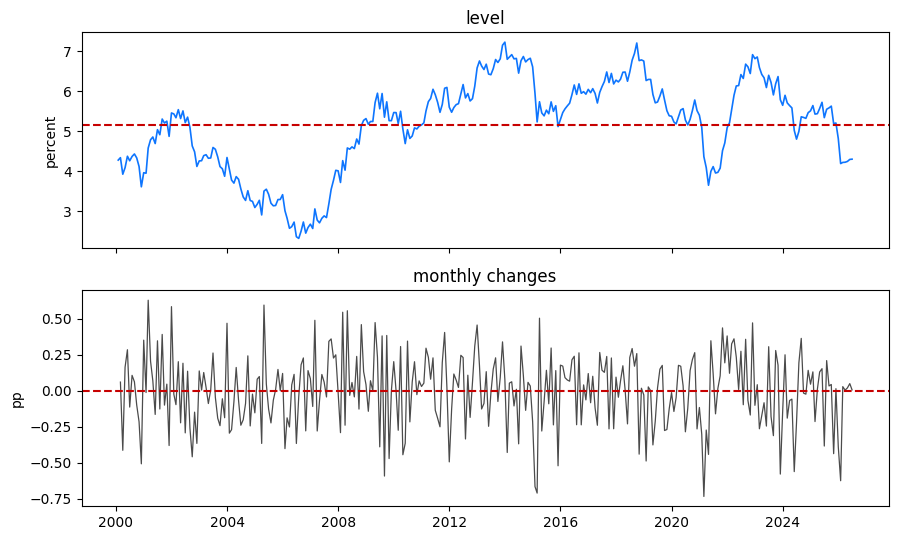

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
axes[0].plot(y.index, y.values, lw=1.2, color='#0E75FE')
axes[0].axhline(y.mean(), ls='--', color='#C70101')
axes[0].set_title('level'); axes[0].set_ylabel('percent')
axes[1].plot(dy.index, dy.values, lw=0.9, color='#4B4B4B')
axes[1].axhline(0, ls='--', color='#C70101')
axes[1].set_title('monthly changes'); axes[1].set_ylabel('pp')
plt.tight_layout(); plt.show()

**Interpretation.** (b) Weak stationarity requires a constant mean, a constant variance, and
autocovariances that depend only on the lag, not on the date. (c) The level wanders in long
swings and spends years away from its sample mean: the mean condition looks violated, so the
series looks non-stationary. The changes fluctuate around zero with a stable spread: all three
conditions look plausible. But an eyeball verdict has no error rates; two econometricians can
stare at the same chart and disagree, which is exactly why the ADF test of Exercises 5 and 6
exists. Test first, regress second.

## Exercise 2: The Difference Operator by Hand
(a) Compute the first difference of the last four observations of `y` by hand from the levels
(print the levels, then subtract on paper or in a comment).
(b) Verify with `y.diff()` that your hand-made numbers agree.
(c) One sentence: what does Delta y measure economically for a yield series, and why does
differencing cost one observation?

In [3]:
last4 = y.iloc[-4:]
print('levels:')
print(last4.round(3))
hand = last4.values[1:] - last4.values[:-1]
print('\nby hand (y_t minus y_(t-1)):', hand.round(3))
print('via y.diff()             :', y.diff().iloc[-3:].values.round(3))

levels:
2026-03-31    4.223
2026-04-30    4.243
2026-05-31    4.294
2026-06-30    4.300
Freq: ME, Name: yield10y, dtype: float64

by hand (y_t minus y_(t-1)): [0.02  0.05  0.006]
via y.diff()             : [0.02  0.05  0.006]


**Interpretation.** (a, b) Both routes give identical numbers: the difference operator is
nothing more than y_t minus y_(t-1), one subtraction per date. (c) Delta y is the monthly
change of the yield in percentage points, the object that behaves like a stationary series
and that Time Series II will build forecasting models on. The first observation has no
predecessor, so one observation is lost per differencing round: n levels give n minus 1
changes (318 levels, 317 changes here).

## Exercise 3: Reading the ACF
(a) Plot the ACF of the level and of the changes (24 lags each).
(b) Report the lag-1 autocorrelation of both series, and the level's ACF at lags 12 and 24.
(c) A geometric decay at a rate of 0.98 per lag would stand at 0.98 to the power 12 after
a year. Compute that value and compare it with your measured lag-12 value. What is the
fingerprint you should remember?

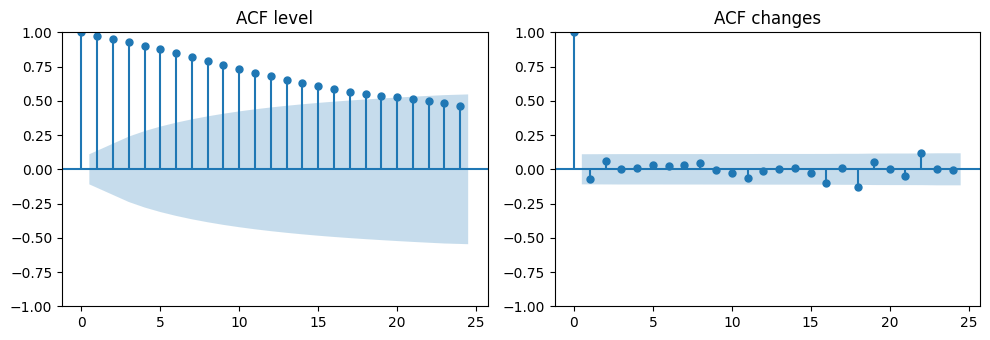

level : lag 1 0.975, lag 12 0.680, lag 24 0.464
changes: lag 1 -0.067
0.98^12 = 0.785


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
plot_acf(y, lags=24, ax=axes[0]); axes[0].set_title('ACF level')
plot_acf(dy, lags=24, ax=axes[1]); axes[1].set_title('ACF changes')
plt.tight_layout(); plt.show()

a_lvl = acf(y, nlags=24); a_chg = acf(dy, nlags=5)
print(f"level : lag 1 {a_lvl[1]:.3f}, lag 12 {a_lvl[12]:.3f}, lag 24 {a_lvl[24]:.3f}")
print(f"changes: lag 1 {a_chg[1]:.3f}")
print(f"0.98^12 = {0.98**12:.3f}")

**Interpretation.** (b) On the fallback data the level's lag-1 autocorrelation is 0.975 and
the ACF still reads 0.68 at lag 12 and 0.46 at lag 24; the changes are essentially zero from
lag 1 on. (c) 0.98 to the power 12 is 0.785 while the measured lag-12 value is 0.68: the same
slow-creep order of magnitude, but a real ACF is not an exact geometric curve. After a
full year the level still remembers most of where it was. The fingerprint: an ACF that creeps
down almost linearly signals a unit root; an ACF that cuts off quickly signals a stationary
series. It is a fingerprint, not a proof: the formal decision comes from the ADF test.

## Exercise 4: Simulate Random Walks and Check the Variance Law
(a) Simulate 2000 random-walk paths of length 100 with N(0, 1) shocks (one seeded generator).
(b) Compute the cross-path variance of the walk at t = 10, 25, 50 and 100 and compare with the
theoretical Var(y_t) = t sigma-squared.
(c) Why does this growing variance violate stationarity, and what does it imply for the
uncertainty of long-horizon forecasts?

In [5]:
rng = np.random.default_rng(7)
paths = np.cumsum(rng.normal(0, 1, size=(2000, 100)), axis=1)
for t in [10, 25, 50, 100]:
    v = paths[:, t-1].var()
    print(f"t = {t:3d}: empirical Var {v:6.1f}   theoretical t*sigma^2 = {t}")

t =  10: empirical Var   10.0   theoretical t*sigma^2 = 10
t =  25: empirical Var   26.4   theoretical t*sigma^2 = 25
t =  50: empirical Var   56.1   theoretical t*sigma^2 = 50
t = 100: empirical Var  104.9   theoretical t*sigma^2 = 100


**Interpretation.** (b) The empirical cross-path variances land close to 10, 25, 50 and 100:
the variance of a random walk grows linearly in t, Var(y_t) = t sigma-squared, because every
shock stays in the level forever and the shocks add up. (c) Stationarity demands a CONSTANT
variance, so the random walk fails the second condition by construction. For forecasting, the
uncertainty band grows like sigma times the square root of t and never closes: the fan chart
of Exercise 8 is this law applied to the yield, and it is why long-horizon point forecasts of
prices and rates carry so little information.

## Exercise 5: The ADF Test on the Level
(a) Run `adfuller` on the yield level with a constant, `autolag='BIC'` and
`result_object=True`, which lets you read the results by name. Report the test
statistic, the p-value and the three critical values.
(b) State H0 and H1 of the test and make the 5 percent decision.
(c) A colleague compares your statistic with -1.645 and announces mean reversion. What exactly
is the mistake?

In [6]:
# statsmodels returns the ADF results as an object whose fields are read by NAME.
# Positional indexing past the first two slots is not part of that API, so the
# whole chapter reads .statistic, .pvalue, .lags, .nobs and .critical_values.
res = adfuller(y, regression='c', autolag='BIC', result_object=True)
print(f"statistic {res.statistic:.2f}, p-value {res.pvalue:.3f}, lags {res.lags} (BIC)")
print("critical values:", {k: round(v, 2) for k, v in res.critical_values.items()})
print("decision at 5%:", 'reject H0' if res.statistic < res.critical_values['5%'] else 'cannot reject H0, unit root stays')

statistic -1.95, p-value 0.311, lags 0 (BIC)
critical values: {'1%': np.float64(-3.45), '5%': np.float64(-2.87), '10%': np.float64(-2.57)}
decision at 5%: cannot reject H0, unit root stays


**Interpretation.** (a) On the fallback data: statistic -1.95, p-value 0.31, critical values
-3.45 / -2.87 / -2.57. Note on the printed critical values: statsmodels computes MacKinnon values for the exact sample size and prints -3.45 here. The course table lists -3.46 at T = 250, -3.44 at T = 500 and -3.43 for T = infinity, and its reading rule takes the nearest SMALLER T, so a sample of 318 reads the T = 250 row, -3.46, which is the value the chapter prints; the decision is the same against every one of them. (b) H0: the series has a unit root (gamma = 0, random walk); H1: gamma
is negative, mean reversion. Since -1.95 is ABOVE -2.87 we cannot reject H0 at 5 percent: the
unit root stays and the yield level behaves like a random walk, matching the handout's -1.92.
(c) Under H0 the t-ratio does not follow the t or normal distribution; its distribution sits
far to the left, which is why the Dickey-Fuller critical values exist. Against -1.645 the
colleague rejects far too often and "discovers" mean reversion that is not there: -1.95 would
wrongly count as significant.

## Exercise 6: The ADF Test on the Changes
(a) Run the same ADF test on the monthly changes `dy`.
(b) Make the decision at the 1 percent level.
(c) Why is running the test twice (level, then changes) the standard routine rather than
overkill?

In [7]:
res_c = adfuller(dy, regression='c', autolag='BIC', result_object=True)
print(f"statistic {res_c.statistic:.2f}, p-value {res_c.pvalue:.4f}, lags {res_c.lags} (BIC)")
print("critical values:", {k: round(v, 2) for k, v in res_c.critical_values.items()})
print("decision at 1%:", 'reject H0, changes stationary' if res_c.statistic < res_c.critical_values['1%'] else 'cannot reject H0')

statistic -18.96, p-value 0.0000, lags 0 (BIC)
critical values: {'1%': np.float64(-3.45), '5%': np.float64(-2.87), '10%': np.float64(-2.57)}
decision at 1%: reject H0, changes stationary


**Interpretation.** (a, b) On the fallback data the statistic is -18.96, far below the 1
percent critical value of -3.45 (see the note in Exercise 5): reject H0 decisively, the monthly changes are stationary
(the handout's illustrative value is -9.84, same verdict). (c) The first test alone only says
the level is not stationary; it does not say one difference is enough. The second test
confirms that differencing once produces a stationary series, which pins down the order of
integration in Exercise 7 and licenses the standard toolbox on Delta y. If the changes had
also kept a unit root, a second difference would be needed, a rare I(2) case worth
double-checking in the data.

## Exercise 7: The I(d) Classification
(a) Based on Exercises 5 and 6, classify the yield in the I(d) language and justify in one
sentence.
(b) State what I(0), I(1) and I(2) mean and which of the three dominates financial level
series.
(c) What information does differencing throw away, and which method (outlook, not exam
material) recovers a shared long-run link between two I(1) series?

In [8]:
res   = adfuller(y,  regression='c', autolag='BIC', result_object=True)
res_c = adfuller(dy, regression='c', autolag='BIC', result_object=True)
lvl_stationary = res.statistic   < res.critical_values['5%']
chg_stationary = res_c.statistic < res_c.critical_values['5%']
if lvl_stationary:
    verdict = 'I(0): stationary in the level'
elif chg_stationary:
    verdict = 'I(1): unit root in the level, stationary after one difference'
else:
    verdict = 'at least I(2): check the data'
print(f"level stationary: {lvl_stationary}, changes stationary: {chg_stationary}")
print('classification:', verdict)

level stationary: False, changes stationary: True
classification: I(1): unit root in the level, stationary after one difference


**Interpretation.** (a) The yield is I(1): the level keeps its unit root (cannot reject H0)
while one difference is stationary (reject at 1 percent), so it is integrated of order one.
(b) I(0) means stationary as it stands, the toolbox applies to the level directly; I(1) means
stationary after differencing once, work with changes and returns; I(2) needs two differences
and is extremely rare. Most financial levels (prices, rates, spreads) are I(1). (c)
Differencing discards the long-run level information: Delta y knows how the yield moves, not
where it is. If two I(1) series share a common trend (spot and futures, two yields),
cointegration methods recover exactly that long-run link.

## Exercise 8: The Random-Walk Forecast Band
(a) Using today's yield and the sd of the monthly changes, compute the random-walk point
forecast and the 95 percent band for h = 1, 6, 12 and 24 months.
(b) Verify the handout's headline number: 1.96 x 0.25 x sqrt(12) for the 12-month band.
(c) Draw the fan chart (flat forecast plus the widening band) and give the one-sentence
humbling lesson.

point forecast at every h: 4.30 percent (today's value)
h =  1: +/- 0.49 pp   (3.81 to 4.79)
h =  6: +/- 1.21 pp   (3.09 to 5.51)
h = 12: +/- 1.70 pp   (2.60 to 6.00)
h = 24: +/- 2.41 pp   (1.89 to 6.71)

handout check: 1.96 * 0.25 * sqrt(12) = 1.70 pp


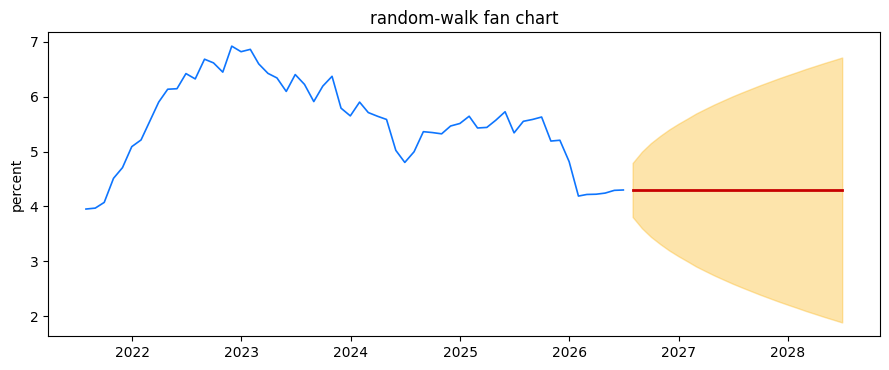

In [9]:
last = y.iloc[-1]; sd = dy.std()
print(f"point forecast at every h: {last:.2f} percent (today's value)")
for h in [1, 6, 12, 24]:
    b = 1.96 * sd * np.sqrt(h)
    print(f"h = {h:2d}: +/- {b:.2f} pp   ({last - b:.2f} to {last + b:.2f})")
print(f"\nhandout check: 1.96 * 0.25 * sqrt(12) = {1.96*0.25*np.sqrt(12):.2f} pp")

H = 24; h_ax = np.arange(1, H + 1); band = 1.96 * sd * np.sqrt(h_ax)
fut = pd.date_range(y.index[-1], periods=H + 1, freq='ME')[1:]
plt.figure(figsize=(9, 3.8))
plt.plot(y.iloc[-60:].index, y.iloc[-60:].values, color='#0E75FE', lw=1.2)
plt.plot(fut, np.full(H, last), color='#C70101', lw=2)
plt.fill_between(fut, last - band, last + band, color='#FCB310', alpha=0.35)
plt.ylabel('percent'); plt.title('random-walk fan chart')
plt.tight_layout(); plt.show()

**Interpretation.** (a) The best point forecast of a random walk is today's value at EVERY
horizon: flat at 4.30 percent on the fallback data. The band grows with the square root of
the horizon: about 0.49 pp at one month and 1.70 pp at twelve (fallback sd 0.251). (b) 1.96
times 0.25 times the square root of 12 equals 1.70 pp, the handout's number. (c) The humbling
lesson of interest-rate forecasting: the point forecast carries no information beyond today's
value, only the widening band does the talking, and one year out the model admits a range of
more than three percentage points.

## Exercise 9: The Spurious Levels Regression
(a) Regress the BTC level on the S&P 500 level (with constant). Report R-squared, the slope
t-statistic and the Durbin-Watson statistic.
(b) Apply the alarm rule of thumb and name the symptom that gives the game away.
(c) Explain, with Granger and Newbold (1974) in one sentence, why the huge t-statistic is not
evidence of a relationship.

In [10]:
reg = sm.OLS(pair['btc'], sm.add_constant(pair['spx'])).fit()
dw = durbin_watson(reg.resid)
print(f"R2 {reg.rsquared:.2f}, slope t {reg.tvalues['spx']:.1f}, DW {dw:.2f}")
print('alarm rule R2 > DW:', 'ALARM, spurious' if reg.rsquared > dw else 'ok')

R2 0.81, slope t 24.1, DW 0.20
alarm rule R2 > DW: ALARM, spurious


**Interpretation.** (a) On the fallback pair: R-squared 0.81, slope t 24.1, DW 0.20 (the
handout's illustrative table: 0.83, 25.8, 0.09). (b) R-squared far above DW: alarm. The symptom
is the Durbin-Watson near zero, i.e. massively autocorrelated residuals: the regression
connects two TRENDS, not two variables, so the residuals crawl instead of hovering around
zero. (c) Granger and Newbold showed that regressing two INDEPENDENT random walks on each
other makes the t-test reject "no relationship" far too often; with trending levels,
significance is manufactured by construction, and the fallback pair is literally two
independent walks, so its t of 24.1 is pure manufacture.

## Exercise 10: The Returns Regression and the Final Verdict
(a) Compute monthly log returns of both series and rerun the regression in returns. Report
R-squared, the slope t-statistic and DW.
(b) Compare levels versus returns in one table and give the verdict on the pair.
(c) State the two cures for spurious regression and the practical workflow you will apply to
every financial series from now on.

In [11]:
rets = np.log(pair).diff().dropna()
reg_r = sm.OLS(rets['btc'], sm.add_constant(rets['spx'])).fit()
dw_r = durbin_watson(reg_r.resid)

reg_l = sm.OLS(pair['btc'], sm.add_constant(pair['spx'])).fit()
dw_l = durbin_watson(reg_l.resid)
tab = pd.DataFrame({'R2': [reg_l.rsquared, reg_r.rsquared],
                    'slope t': [reg_l.tvalues['spx'], reg_r.tvalues['spx']],
                    'DW': [dw_l, dw_r]}, index=['LEVELS', 'RETURNS']).round(2)
print(tab)

           R2  slope t    DW
LEVELS   0.81    24.12  0.20
RETURNS  0.03     1.87  1.98

**Interpretation.** (a, b) On the fallback pair the returns regression reads R-squared 0.03,
t 1.9, DW 1.98 against the levels' 0.81 / 24.1 / 0.20. The verdict: the spectacular levels
result is an illusion; in returns the honest answer appears, which for two independent walks
is "no reliable relationship" (the handout's illustrative figures show a small but real comovement,
R-squared 0.04, t 2.4, DW 1.98). (c) Cure one, today's tool: difference to returns before
regressing. Cure two, outlook: if two I(1) series share a common trend, model it directly with
cointegration methods. The workflow for every series: test stationarity first (ADF), classify
I(d), difference I(1) series once, and only then estimate, diagnose and forecast.